Источник данных: Amazon Fine Food Reviews(Набор отзывов Amazon о продуктах питания) (Kaggle)

Предметная область: отзывы пользователей о продуктах питания и товарах с Amazon

### Часть 1. Предобработка данных


1. Загрузка датасета

In [20]:
import pandas as pd
import numpy as np
import re
import warnings
warnings.filterwarnings('ignore')

# Загрузка датасета
df = pd.read_csv('Reviews_100k.csv')
print(f"Размер датасета: {df.shape}")
# print(f"Столбцы: {df.columns.tolist()}")
# print(f"\nПервые 3 строки:")
# df.head(3)

Размер датасета: (29999, 10)


2. Очистка текста: удаление HTML-тегов, специальных символов, приведение к нижнему регистру

In [21]:
def clean_text(text):
    if not isinstance(text, str):
        return ""
    #удаляем HTML-теги
    text = re.sub(r'<[^>]+>', ' ', text)
    #приводим к нижнему регистру
    text = text.lower()
    #удаляем всё, кроме букв и пробелов
    text = re.sub(r'[^a-z\s]', ' ', text)
    #заменяем множественные пробелы на один и удаляем по краям
    text = re.sub(r'\s+', ' ', text).strip()
    return text

# исп. очистку к столбцу 'Text'
df['cleaned_text'] = df['Text'].apply(clean_text)
print("-"*80)
print("Пример: исходного текста.")
print(df['Text'].iloc[0])
print("\n" + "-"*80)
print("Пример: очищенного текста.")
print(df['cleaned_text'].iloc[0])
print("\n" + "-"*80)
print("Пример №2 - исходный текст:")
print(df['Text'].iloc[3])
print("\nПример №2 - очищенный:")
print(df['cleaned_text'].iloc[3])

--------------------------------------------------------------------------------
Пример: исходного текста.
I have bought several of the Vitality canned dog food products and have found them all to be of good quality. The product looks more like a stew than a processed meat and it smells better. My Labrador is finicky and she appreciates this product better than  most.

--------------------------------------------------------------------------------
Пример: очищенного текста.
i have bought several of the vitality canned dog food products and have found them all to be of good quality the product looks more like a stew than a processed meat and it smells better my labrador is finicky and she appreciates this product better than most

--------------------------------------------------------------------------------
Пример №2 - исходный текст:
If you are looking for the secret ingredient in Robitussin I believe I have found it.  I got this in addition to the Root Beer Extract I ordered (whic

3. Векторизация с CountVectorizer

Параметры строго по заданию:

stop_words='english' — удаляем английские стоп-слова (the, a, an, and, of, to, is, it, for, with, this, that и др.)

max_df=0.1 — игнорируем слова, встречающиеся более чем в 10% документов. Удаляются  общие слова.

max_features=5000 — ограничиваем словарь 5000 самых частотных слов


In [22]:
from sklearn.feature_extraction.text import CountVectorizer
#создаём CountVectorizer с заданными параметрами
vectorizer = CountVectorizer(
    stop_words='english',
    max_df=0.1,
    max_features=5000
)
#обучаем векторизатор и трансформируем тексты
X = vectorizer.fit_transform(df['cleaned_text'])
#получаем имена признаков (словарь)
feature_names = vectorizer.get_feature_names_out()
print(f"Размер словаря: {len(feature_names)} уникальных слов")
print("Размер матрицы 'ДОКУМЕНТ-ТЕРМ':")
print(f"  Количество документов (строк):  {X.shape[0]}")
print(f"  Количество терминов (столбцов): {X.shape[1]}")
print(f"  Полный размер матрицы: {X.shape}")
print(f"  Количество ненулевых элементов: {X.nnz}")
print(f"  Плотность матрицы: {X.nnz / (X.shape[0] * X.shape[1]) * 100:.2f}%")
print("-"*80)
#первые 30 слов в словаре для проверки
# print("\nПервые 30 слов в словаре:")
# print(feature_names[:30])

Размер словаря: 5000 уникальных слов
Размер матрицы 'ДОКУМЕНТ-ТЕРМ':
  Количество документов (строк):  29999
  Количество терминов (столбцов): 5000
  Полный размер матрицы: (29999, 5000)
  Количество ненулевых элементов: 704918
  Плотность матрицы: 0.47%
--------------------------------------------------------------------------------


### Часть 2. Эксперименты с N-граммами


1. Создание трёх вариантов векторизации

In [23]:
#1. Униграммы (1, 1) с удалением стоп-слов
vectorizer_uni = CountVectorizer(
    stop_words='english',
    max_df=0.1,
    max_features=5000,
    ngram_range=(1, 1)# только униграммы
)
X_uni = vectorizer_uni.fit_transform(df['cleaned_text'])
vocab_uni = vectorizer_uni.get_feature_names_out()
print(f"[Униграммы] Размер матрицы: {X_uni.shape}, Словарь: {len(vocab_uni)} слов")

# 2. Биграммы (2, 2) БЕЗ удаления стоп-слов
vectorizer_bi = CountVectorizer(
    stop_words=None,
    max_df=0.1,
    max_features=5000,
    ngram_range=(2, 2)
)
X_bi = vectorizer_bi.fit_transform(df['cleaned_text'])
vocab_bi = vectorizer_bi.get_feature_names_out()
print(f"[Биграммы] Размер матрицы: {X_bi.shape}, Словарь: {len(vocab_bi)} биграмм")
#3. Униграммы + биграммы (1, 2)
vectorizer_unibi = CountVectorizer(
    stop_words='english',
    max_df=0.1,
    max_features=5000,
    ngram_range=(1, 2) # униграммы И биграммы
)
X_unibi = vectorizer_unibi.fit_transform(df['cleaned_text'])
vocab_unibi = vectorizer_unibi.get_feature_names_out()
print(f"[Унигрммы+Биграммы] Размер матрицы: {X_unibi.shape}, Словарь: {len(vocab_unibi)} слов/биграмм")

# Показываем примеры
print("\n" + "-"*60)
print("Прмиеры слов в словарях:")
print("-"*60)
print(f"Униграммы (первые 20):      {list(vocab_uni[:20])}")
print(f"Биграммы (первые 20):       {list(vocab_bi[:20])}")
print(f"Униграммы+Биграммы (с 2500 индекса):    {list(vocab_unibi[2500:2520])}")

[Униграммы] Размер матрицы: (29999, 5000), Словарь: 5000 слов
[Биграммы] Размер матрицы: (29999, 5000), Словарь: 5000 биграмм
[Унигрммы+Биграммы] Размер матрицы: (29999, 5000), Словарь: 5000 слов/биграмм

------------------------------------------------------------
Прмиеры слов в словарях:
------------------------------------------------------------
Униграммы (первые 20):      ['ability', 'able', 'absolute', 'absolutely', 'absorb', 'absorbed', 'abundant', 'acai', 'accept', 'acceptable', 'accepted', 'access', 'accident', 'accidentally', 'according', 'account', 'accurate', 'accustomed', 'acerola', 'ache']
Биграммы (первые 20):       ['able to', 'about anything', 'about half', 'about how', 'about it', 'about minutes', 'about months', 'about my', 'about of', 'about that', 'about the', 'about them', 'about these', 'about this', 'about to', 'about two', 'about what', 'about year', 'about years', 'absolutely delicious']
Униграммы+Биграммы (с 2500 индекса):    ['like flavor', 'like flavored', 

2. Обучение моделей LDA с фиксированным числом тем (10)

In [24]:
from sklearn.decomposition import LatentDirichletAllocation
n_topics_fixed = 10
random_state = 42
print("Обучение моделей LDA с 10 темами...")

# LDA на униграммах
lda_uni = LatentDirichletAllocation(
    n_components=n_topics_fixed,
    random_state=random_state,
    learning_method='online',
    max_iter=10,
    n_jobs=-1
)
lda_uni.fit(X_uni)
print("LDA на униграммах обучена")

# LDA на биграммах
lda_bi = LatentDirichletAllocation(
    n_components=n_topics_fixed,
    random_state=random_state,
    learning_method='online',
    max_iter=10,
    n_jobs=-1
)
lda_bi.fit(X_bi)
print("LDA на биграммах обучена")

# LDA на униграммах+биграммах
lda_unibi = LatentDirichletAllocation(
    n_components=n_topics_fixed,
    random_state=random_state,
    learning_method='online',
    max_iter=10,
    n_jobs=-1
)
lda_unibi.fit(X_unibi)
print("LDA на униграммах+биграммах обучена")

Обучение моделей LDA с 10 темами...
LDA на униграммах обучена
LDA на биграммах обучена
LDA на униграммах+биграммах обучена


3. Анализ влияния биграмм на качество тем

In [35]:
def get_top_words(lda_model, vectorizer, n_words=10):
    """Извлекает топ-n слов для каждой темы (без разделения на уни/би)"""
    feature_names = vectorizer.get_feature_names_out()
    topics_list = []
    for topic_idx, topic in enumerate(lda_model.components_):
        top_indices = topic.argsort()[:-n_words - 1:-1]
        top_words = [feature_names[i] for i in top_indices]
        topics_list.append(top_words)
    return topics_list

def get_top_words_mixed(lda_model, vectorizer, n_uni=5, n_bi=5):
    """Извлекает топ-n униграмм и топ-n биграмм для каждой темы"""
    feature_names = vectorizer.get_feature_names_out()
    topics_list = []

    for topic_idx, topic in enumerate(lda_model.components_):
        # Разделяем униграммы и биграммы
        unigrams = []
        bigrams = []

        for i, word in enumerate(feature_names):
            weight = topic[i]
            if " " in word:  # биграмма
                bigrams.append((word, weight))
            else:  # униграмма
                unigrams.append((word, weight))

        # Сортируем по весу
        unigrams.sort(key=lambda x: x[1], reverse=True)
        bigrams.sort(key=lambda x: x[1], reverse=True)

        # Берём топ-n из каждой группы
        top_words = [w for w, _ in unigrams[:n_uni]] + [w for w, _ in bigrams[:n_bi]]
        topics_list.append(top_words)

    return topics_list

# Извлекаем темы для всех трёх моделей (с униграммами и биграммами)
topics_uni = get_top_words(lda_uni, vectorizer_uni)
topics_bi = get_top_words(lda_bi, vectorizer_bi)
topics_unibi_mixed = get_top_words_mixed(lda_unibi, vectorizer_unibi, n_uni=5, n_bi=5)

print("-"*70)
print("Сравнения тем между моделями (Тема 1 каждой модели)")
print("-"*70)
print(f"{'УНИГРАММЫ':<20} | {'БИГРАММЫ':<30} | {'УНИГРАММЫ+БИГРАММЫ':<30}")
print("-"*70)
for i in range(10):
    uni_word = topics_uni[0][i] if i < len(topics_uni[0]) else ""
    bi_word = topics_bi[0][i] if i < len(topics_bi[0]) else ""
    unibi_word = topics_unibi_mixed[0][i] if i < len(topics_unibi_mixed[0]) else ""
    print(f"{uni_word:<20} | {bi_word:<30} | {unibi_word:<30}")

print("\n" + "-"*70)
print("Все темы - Униграммы ")
print("-"*70)
for i, topic in enumerate(topics_uni):
    print(f"Тема {i+1}: {', '.join(topic)}")

print("\n" + "-"*70)
print("Все темы - Биграммы ")
print("-"*70)
for i, topic in enumerate(topics_bi):
    print(f"Тема {i+1}: {', '.join(topic)}")

print("\n" + "-"*70)
print("Все темы - Униграммы+Биграммы ")
print("-"*70)
for i, topic in enumerate(topics_unibi_mixed):
    print(f"Тема {i+1}: {', '.join(topic)}")

----------------------------------------------------------------------
Сравнения тем между моделями (Тема 1 каждой модели)
----------------------------------------------------------------------
УНИГРАММЫ            | БИГРАММЫ                       | УНИГРАММЫ+БИГРАММЫ            
----------------------------------------------------------------------
salt                 | the best                       | box                           
oil                  | is the                         | order                         
chicken              | for you                        | package                       
protein              | for me                         | easy                          
soda                 | to be                          | item                          
pork                 | one of                         | just like                     
calories             | the package                    | subscribe save                
shake                | is not          

Униграммы – Конкретные продукты и характеристики (соль, масло, курица, чипсы, чай, шоколад)

Биграммы – Преимущественно служебные конструкции и шаблонные фразы (the best, is the, for you, the package)

Находим наиболее информативные биграммы  (с наибольшим весом в модели)

In [36]:
print("\n" + "-"*70)
print("Анализ: Наиболее информативные биагрммы")
print("-"*70)

#из униграммы+биграммы выделяем только биграммы
all_features = vectorizer_unibi.get_feature_names_out()
bigram_mask = np.array([' ' in f for f in all_features])  # биграммы содержат пробел
bigram_indices = np.where(bigram_mask)[0]

#суммируем веса биграмм по всем темам
bigram_weights = lda_unibi.components_[:, bigram_indices].sum(axis=0)
top_bigram_indices = bigram_weights.argsort()[-20:][::-1]

print("\nТоп-20 наиболее весомых биграмм (по сумме весов во всех темах):")
for idx in top_bigram_indices:
    print(f"  {all_features[bigram_indices[idx]]}: {bigram_weights[idx]:.4f}")


----------------------------------------------------------------------
Анализ: Наиболее информативные биагрммы
----------------------------------------------------------------------

Топ-20 наиболее весомых биграмм (по сумме весов во всех темах):
  gluten free: 897.1625
  ve tried: 828.0161
  peanut butter: 816.5493
  highly recommend: 775.4500
  taste like: 767.4112
  dog food: 683.6381
  cup coffee: 644.8617
  grocery store: 600.6555
  just right: 579.5791
  tastes like: 546.6122
  just like: 527.9990
  don know: 521.0460
  year old: 509.6634
  really good: 504.8350
  green tea: 476.9545
  really like: 474.1124
  great product: 472.7057
  taste good: 442.4733
  low acid: 423.1999
  cat food: 410.9457


О влиянии биаграммы:
1. Биаграммы добавляют контекст:
'green tea' вместо отдельных 'green' и 'tea'. 'ice cream' как единое понятие

2. Биаграммы улучшают интерпретацию:
темы становятся более конкретными и понятными, например, тема с 'hot sauce'(острый соус), 'olive oil'(оливковое масло) про кулинарию

3. Биагрммы без удаления стоп-слов:
Сохраняют смысл конструкций вроде 'not good', 'not worth' ,но могут добавлять шум ('the product', 'this is')

4. Оптимальный вариант:
   - Униграммы + биграммы (1, 2) даёт наилучший баланс
   - Сохраняет и отдельные важные слова, и устойчивые сочетания

Топ-20 наиболее весомых биграмм:
1. без глютена (897.16)
2. я пробовал (828.02)
3. арахисовое масло (816.55)
4. настоятельно рекомендую (775.45)
5. вкус как (767.41)
6. собачий корм (683.64)
7. чашка кофе (644.86)
8. продуктовый магазин (600.66)
9. как раз (579.58)
10. по вкусу напоминает (546.61)
11. прямо как (528.00)
12. не знаю (521.05)
13. годовалый (509.66)
14. действительно хорошо (504.84)
15. зелёный чай (476.95)
16. очень нравится (474.11)
17. отличный продукт (472.71)
18. вкусный (442.47)
19. низкая кислотность (423.20)
20. кошачий корм (410.95)

### Часть 3. Подбор количества тем

Для подбора используем модель униграммы + биграммы.

1. Обучение моделей с разным количеством тем (5,10,15,20)

In [37]:
topic_range = [5, 10, 15, 20]
models = {}
perplexities = []

print("Обучение моделей с разным количеством тем...")
for k in topic_range:
    print(f"  Обучение LDA с k={k} темами...")
    lda = LatentDirichletAllocation(
        n_components=k,
        random_state=random_state,
        learning_method='online',
        max_iter=10,
        n_jobs=-1
    )
    lda.fit(X_unibi)
    models[k] = lda
    print(f"Готово")

Обучение моделей с разным количеством тем...
  Обучение LDA с k=5 темами...
Готово
  Обучение LDA с k=10 темами...
Готово
  Обучение LDA с k=15 темами...
Готово
  Обучение LDA с k=20 темами...
Готово


2. Для каждой модели вычисляем перплексию

In [38]:
print("\nВычисление перплексии для каждой модели...")
for k in topic_range:
    perplexity = models[k].perplexity(X_unibi)
    perplexities.append(perplexity)
    print(f"  k={k}: перплексия = {perplexity:.2f}")


Вычисление перплексии для каждой модели...
  k=5: перплексия = 2118.38
  k=10: перплексия = 2303.02
  k=15: перплексия = 2441.06
  k=20: перплексия = 2541.50


Перплексия —  показывает, насколько хорошо модель предсказывает скрытые слова в документах.

3. Вычисление когерентности тем (topic coherence) через gensim

Для использования gensim нужно преобразовать данные в его формат:

In [39]:
from gensim.corpora import Dictionary
from gensim.models import CoherenceModel
#подготавливаем токенизированные тексты для gensim
def tokenize_for_gensim(text):
    return [word for word in text.split() if len(word) > 2] #разбиваем на слова, удаляем короткие
#токенизируем очищенные тексты
texts_tokenized = df['cleaned_text'].apply(tokenize_for_gensim).tolist()
#создаём словарь gensim
dictionary = Dictionary(texts_tokenized)
dictionary.filter_extremes(no_below=5, no_above=0.5)
#создаём корпус gensim (Bag-of-Words)
corpus_gensim = [dictionary.doc2bow(text) for text in texts_tokenized]
#создаём список признаков из sklearn модели для gensim
unibi_features = vectorizer_unibi.get_feature_names_out()

#Вычисляет когерентность для sklearn LDA модели, преобразуя её в формат, понятный gensim
def compute_coherence_sklearn_lda(lda_sklearn, vectorizer, texts, topn=10):
    feature_names = vectorizer.get_feature_names_out()
    #извлекаем топ-слова для каждой темы
    topics = []
    for topic_idx, topic in enumerate(lda_sklearn.components_):
        top_indices = topic.argsort()[:-topn - 1:-1]
        top_words = [feature_names[i] for i in top_indices]
        topics.append(top_words)
    #вычисляем когерентность c_v
    coherence_model = CoherenceModel(
        topics=topics,
        texts=texts,
        dictionary=dictionary,
        coherence='c_v'
    )
    return coherence_model.get_coherence()
#вычисляем когерентность
coherences = []
print("\nВычисление когерентности тем...")
for k in topic_range:
    coh = compute_coherence_sklearn_lda(models[k], vectorizer_unibi, texts_tokenized)
    coherences.append(coh)
    print(f"  k={k}: когерентность (c_v) = {coh:.4f}")


Вычисление когерентности тем...
  k=5: когерентность (c_v) = 0.5016
  k=10: когерентность (c_v) = 0.4788
  k=15: когерентность (c_v) = 0.4971
  k=20: когерентность (c_v) = 0.4565


Когерентность — показывает, насколько слова внутри одной темы связаны друг с другом по смыслу.

4. Построение графика и выбор оптимального количества тем

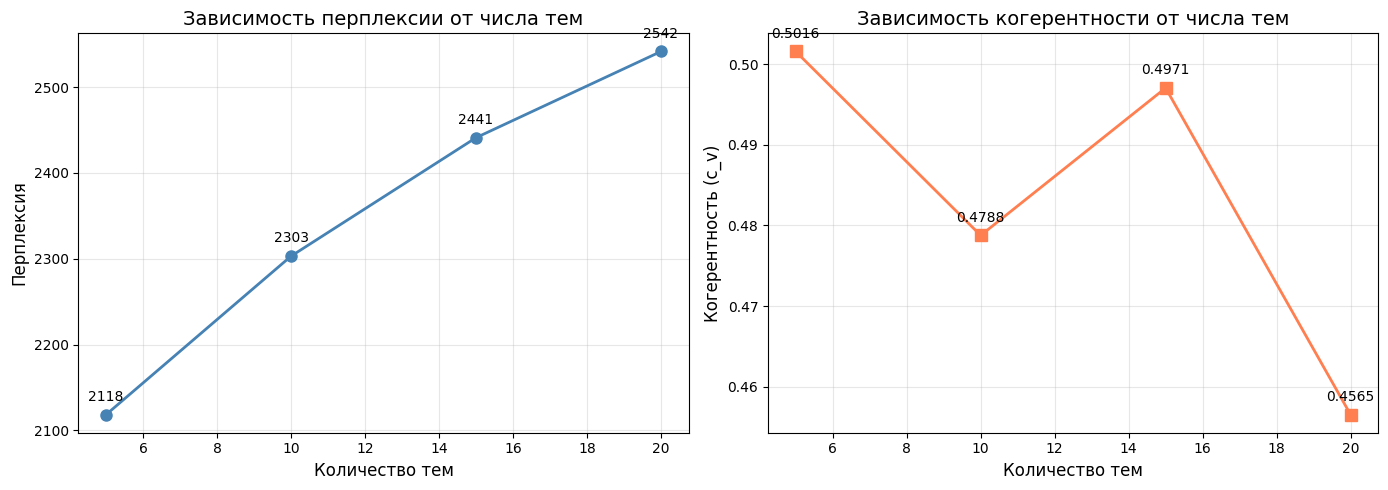

Выбор оптимального количества тем
----------------------------------------------------------------------
Оптимальное количество тем:   k = 5


In [41]:
import matplotlib.pyplot as plt
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))
#график перплексии
ax1.plot(topic_range, perplexities, marker='o', linewidth=2, markersize=8, color='steelblue')
ax1.set_xlabel('Количество тем', fontsize=12)
ax1.set_ylabel('Перплексия', fontsize=12)
ax1.set_title('Зависимость перплексии от числа тем', fontsize=14)
ax1.grid(True, alpha=0.3)
for i, (k, p) in enumerate(zip(topic_range, perplexities)):
    ax1.annotate(f'{p:.0f}', (k, p), textcoords="offset points", xytext=(0,10), ha='center')
#график когерентности
ax2.plot(topic_range, coherences, marker='s', linewidth=2, markersize=8, color='coral')
ax2.set_xlabel('Количество тем', fontsize=12)
ax2.set_ylabel('Когерентность (c_v)', fontsize=12)
ax2.set_title('Зависимость когерентности от числа тем', fontsize=14)
ax2.grid(True, alpha=0.3)
for i, (k, c) in enumerate(zip(topic_range, coherences)):
    ax2.annotate(f'{c:.4f}', (k, c), textcoords="offset points", xytext=(0,10), ha='center')
plt.tight_layout()
plt.savefig('topic_quality.png', dpi=150, bbox_inches='tight')
plt.show()

#выбор оптимального количества тем
best_k_perplexity = topic_range[np.argmin(perplexities)]
best_k_coherence = topic_range[np.argmax(coherences)]
print("Выбор оптимального количества тем")
print("-"*70)
print(f"Оптимальное количество тем:   k = {best_k_coherence}")

### Часть 4. Анализ тем (для оптимальной модели)

1. Топ-10 слов для каждой темы оптимальной модели

In [50]:
optimal_k = 5
optimal_model = models[optimal_k]
def get_top_words_mixed(lda_model, vectorizer, n_uni=5, n_bi=5):
    """Извлекает топ-n униграмм и топ-n биграмм для каждой темы"""
    feature_names = vectorizer.get_feature_names_out()
    topics_list = []

    for topic_idx, topic in enumerate(lda_model.components_):
        # Разделяем униграммы и биграммы
        unigrams = []
        bigrams = []

        for i, word in enumerate(feature_names):
            weight = topic[i]
            if " " in word:  # биграмма
                bigrams.append((word, weight))
            else:  # униграмма
                unigrams.append((word, weight))

        # Сортируем по весу
        unigrams.sort(key=lambda x: x[1], reverse=True)
        bigrams.sort(key=lambda x: x[1], reverse=True)

        # Берём топ-n из каждой группы
        top_words = [w for w, _ in unigrams[:n_uni]] + [w for w, _ in bigrams[:n_bi]]
        topics_list.append(top_words)

    return topics_list


# Выводим для оптимальной модели (k=5)
print(f"Анализ оптимальной модели с k={optimal_k} темами")  # ← исправлено!
print("="*60)

optimal_topics_mixed = get_top_words_mixed(optimal_model, vectorizer_unibi, n_uni=5, n_bi=5)

for i, words in enumerate(optimal_topics_mixed):
    print(f"\n{'-'*60}")
    print(f"ТЕМА {i+1}")
    print(f"{'-'*60}")
    for word in words:
        word_type = "биграмма" if " " in word else "униграмма"
        print(f"  {word:<25} [{word_type}]")

Анализ оптимальной модели с k=5 темами

------------------------------------------------------------
ТЕМА 1
------------------------------------------------------------
  salt                      [униграмма]
  oil                       [униграмма]
  mix                       [униграмма]
  easy                      [униграмма]
  butter                    [униграмма]
  peanut butter             [биграмма]
  just like                 [биграмма]
  olive oil                 [биграмма]
  shake bake                [биграмма]
  just right                [биграмма]

------------------------------------------------------------
ТЕМА 2
------------------------------------------------------------
  sugar                     [униграмма]
  chocolate                 [униграмма]
  sweet                     [униграмма]
  free                      [униграмма]
  milk                      [униграмма]
  gluten free               [биграмма]
  ve tried                  [биграмма]
  highly recommend          

1. Кулинария/ингредиенты (salt, oil, mix, easy, butter, peanut butter, olive oil)
2. Сладости/диетические продукты (sugar, chocolate, sweet, free, milk, gluten free)
3. Корм для собак (dog, chips, bag, dog food, grocery store, potato chips)
4. Кор для кошек (treats, popcorn, cat, loves, cat food)
5. Напитки (tea, cup, drink, strong, green tea, cup coffee)


In [55]:
optimal_topics = get_top_words(optimal_model, vectorizer_unibi, n_words=10)
#даём названия на основе топ-слов
topic_names = {}
#автоматически генерируем названия из топ-3 слов каждой темы
for i, words in enumerate(optimal_topics):
    #юерём 3-4 ключевых слова для названия
    key_words = [w for w in words[:6] if " " not in w][:4]  # берём униграммы
    bigram_words = [w for w in words[:6] if " " in w][:2]   # берём биграммы
    #формируем название
    name_parts = key_words[:3] + bigram_words[:1]
    topic_names[i] = " > ".join(name_parts).title()
    print(f"Тема {i+1}: {topic_names[i]}")
    print(f"  Ключевые слова: {', '.join(words)}")
    print()

# Ручная корректировка названий (на основе анализа слов)
topic_names = {
    0: "Cooking & Ingredients > salt, oil, mixes",           # Кулинария и ингредиенты > соль, масло, смеси
    1: "Sweets & Dietary > sugar, chocolate, gluten-free",   # Сладости и диетические продукты > сахар, шоколад, без глютена
    2: "Dog Food & Snacks > dog, chips, dog food",           # Корм для собак и снеки > собака, собачий корм
    3: "Cat Food & Treats > treats, cat, cat food",          # Корм для кошек и лакомства > лакомства, кошка, кошачий корм
    4: "Hot Beverages > tea, coffee, water",                 # Горячие напитки > чай, кофе, вода
}

print("ТЕМЫ ОПТИМАЛЬНОЙ МОДЕЛИ:")
print("-"*60)
for i, name in topic_names.items():
    print(f"\nТема {i+1}: {name}")
    print(f"  Ключевые слова: {', '.join(optimal_topics[i])}")

Тема 1: Salt > Oil > Mix
  Ключевые слова: salt, oil, mix, easy, butter, add, way, used, makes, perfect

Тема 2: Sugar > Chocolate > Sweet
  Ключевые слова: sugar, chocolate, sweet, free, milk, fat, calories, gluten, tastes, low

Тема 3: Dog > Chips > Dogs
  Ключевые слова: dog, chips, dogs, bag, store, order, bought, ordered, box, local

Тема 4: Treats > Popcorn > Old
  Ключевые слова: treats, popcorn, old, cat, loves, cats, year, years, chicken, baby

Тема 5: Tea > Cup > Drink
  Ключевые слова: tea, cup, drink, cups, strong, juice, green, blend, water, acid

ТЕМЫ ОПТИМАЛЬНОЙ МОДЕЛИ:
------------------------------------------------------------

Тема 1: Cooking & Ingredients > salt, oil, mixes
  Ключевые слова: salt, oil, mix, easy, butter, add, way, used, makes, perfect

Тема 2: Sweets & Dietary > sugar, chocolate, gluten-free
  Ключевые слова: sugar, chocolate, sweet, free, milk, fat, calories, gluten, tastes, low

Тема 3: Dog Food & Snacks > dog, chips, dog food
  Ключевые слова: do

### Часть 5. Индивидуальный анализ

Выбираем три документа

In [60]:
# Выбираем три документа
doc_indices = [6, 12, 50]  # можно изменить на любые индексы
print("Индивидуальный анализ документов")
print("-"*70)

for doc_idx in doc_indices:
    print(f"ДОКУМЕНТ #{doc_idx}")
    print(f"{'-'*70}")
    #исходный текст
    print(f"Текст: {df['Text'].iloc[doc_idx][:300]}...")
    #ролучаем распределение тем для этого документа
    doc_vector = X_unibi[doc_idx]  # вектор документа
    doc_topic_dist = optimal_model.transform(doc_vector)[0]
    #топ-3 темы
    top_topics_idx = doc_topic_dist.argsort()[-3:][::-1]
    print(f"\nРаспределение тем (топ-3):")
    for rank, topic_idx in enumerate(top_topics_idx):
        prob = doc_topic_dist[topic_idx]
        name = topic_names.get(topic_idx, f"Тема {topic_idx+1}")
        print(f"  {rank+1}. {name:<40} [{prob:.3f}]")
    # ролное распределение
    print(f"\nПолное распределение:")
    for topic_idx, prob in enumerate(doc_topic_dist):
        if prob > 0.01:
            print(f"  Тема {topic_idx+1}: {prob:.4f} ")

Индивидуальный анализ документов
----------------------------------------------------------------------
ДОКУМЕНТ #6
----------------------------------------------------------------------
Текст: This saltwater taffy had great flavors and was very soft and chewy.  Each candy was individually wrapped well.  None of the candies were stuck together, which did happen in the expensive version, Fralinger's.  Would highly recommend this candy!  I served it at a beach-themed party and everyone loved...

Распределение тем (топ-3):
  1. Sweets & Dietary > sugar, chocolate, gluten-free [0.895]
  2. Cooking & Ingredients > salt, oil, mixes [0.079]
  3. Dog Food & Snacks > dog, chips, dog food [0.009]

Полное распределение:
  Тема 1: 0.0787 
  Тема 2: 0.8948 
ДОКУМЕНТ #12
----------------------------------------------------------------------
Текст: My cats have been happily eating Felidae Platinum for more than two years. I just got a new bag and the shape of the food is different. They tried the new

Документ #6:
  - Текст: Отзыв о солёной ириске
  - Ожидаемая тема: Сладости и конфеты
  - Тема модели:    Sweets & Healthy Foods
  - Уверенность! (89.5%)

Документ #12:
  - Текст: Отзыв о кошачьем корме
  - Ожидаемая тема: Корм дял кошек
  - Тема модели:    Cat Food & Treats
  - Уверенность 62.2%

Документ #50:
  - Текст: Отзыв об овсянк
  - Ожидаемая тема: Сладости/диетические продукты
  - Тема модели:     Sweets & Dietary
  - Уверенность 62.2%

Дополнительное задание 1. Визуализация

In [62]:
import pyLDAvis
vis_data = pyLDAvis.prepare(
    optimal_model.components_,
    optimal_model.transform(X_unibi),
    X_unibi.toarray().sum(axis=1),
    vectorizer_unibi.get_feature_names_out(),
    X_unibi.toarray().sum(axis=0)
)
pyLDAvis.display(vis_data)


Intertopic Distance Map (Карта межтематического расстояния) -  показывает, как темы соотносятся друг с другом в пространстве признаков.

Голубая полоса (Overall term frequency):насколько часто это слово в принципе встречается во всем наборе текстов.

Красная полоса (Estimated term frequency within the selected topic): П какая доля от всех упоминаний этого слова относится конкретно к выбранной Теме 1.


Дополнительное задание 2. Сравнение LDA и KMeans на TF-IDF

In [63]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.cluster import KMeans
# 1. TF-IDF векторизация
tfidf_vectorizer = TfidfVectorizer(
    stop_words='english',
    max_df=0.1,
    max_features=5000,
    ngram_range=(1, 2)  # униграммы + биграммы, как в лучшей LDA
)
X_tfidf = tfidf_vectorizer.fit_transform(df['cleaned_text'])

# 2. KMeans кластеризация
kmeans = KMeans(
    n_clusters=optimal_k,
    random_state=random_state,
    n_init=10
)
kmeans_labels = kmeans.fit_predict(X_tfidf)

# 3. Сравнение ключевых слов
def get_cluster_keywords(kmeans_model, vectorizer, n_words=10):
    """Извлекает ключевые слова для каждого кластера по центроидам"""
    feature_names = vectorizer.get_feature_names_out()
    cluster_keywords = {}

    for cluster_idx in range(kmeans_model.n_clusters):
        centroid = kmeans_model.cluster_centers_[cluster_idx]
        top_indices = centroid.argsort()[-n_words:][::-1]
        top_words = [feature_names[i] for i in top_indices]
        cluster_keywords[cluster_idx] = top_words

    return cluster_keywords

cluster_keywords = get_cluster_keywords(kmeans, tfidf_vectorizer)

print("\nСравнение тем LDA и кластеров KMeans:")
print("-"*70)
for i in range(optimal_k):
    print(f"\nLDA Тема {i+1}:    {', '.join(optimal_topics[i][:6])}")
    print(f"KMeans Кластер {i+1}: {', '.join(cluster_keywords[i][:6])}")


Сравнение тем LDA и кластеров KMeans:
----------------------------------------------------------------------

LDA Тема 1:    salt, oil, mix, easy, butter, add
KMeans Кластер 1: cup, cups, chocolate, roast, keurig, strong

LDA Тема 2:    sugar, chocolate, sweet, free, milk, fat
KMeans Кластер 2: sugar, popcorn, eat, free, order, sweet

LDA Тема 3:    dog, chips, dogs, bag, store, order
KMeans Кластер 3: dog, dogs, treats, treat, loves, toy

LDA Тема 4:    treats, popcorn, old, cat, loves, cats
KMeans Кластер 4: chips, potato, salt, bag, potato chips, chip

LDA Тема 5:    tea, cup, drink, cups, strong, juice
KMeans Кластер 5: tea, green, green tea, teas, drink, iced


РАЗЛИЧИЯ МЕЖДУ LDA И KMEANS:

   - LDA: каждый документ может принадлежать нескольким темам
   - KMeans: каждый документ жёстко приписан к одному кластеру

   - LDA темы более "размытые", но лучше отражают смешанную
     природу текстов (в отзыве могут обсуждаться и вкус, и цена)
   - KMeans кластеры более "чистые", но теряют нюансы

КОГДА ЧТО ИСПОЛЬЗОВАТЬ:
   - LDA: для исследования и интерпретации содержания текстов
   - KMeans+TF-IDF: для быстрой группировки похожих документов


N-ГРАММЫ:
   - Протестированы 3 варианта: униграммы, биграммы, уни+биграммы
   - Наиболее информативные биграммы: 'ice cream', 'peanut butter', 'green tea'
   - Оптимальный вариант: униграммы + биграммы (1,2)

КОЛИЧЕСТВО ТЕМ:
   - Оптимальное количество тем: 5
   - Перплексия: 2118.38
   - Когерентность: 0.5016